# 03 · Reclassifier development

**Question:** does the rule-based reclassifier (lib `classify_track`, config v0.1) label photons more like the G-LiHT and UAV
reference than ATL08 v007 does, especially ground-vs-canopy in short vegetation and canopy-top photons in tall forest?

The algorithm, step by step (all thresholds in `config/atl03_reclass_v0.1.yaml` → `reclass`):
1. **Signal vs noise.** For each photon, count neighbours in a box ±10 m along track × ±1.5 m vertically. Signal if the count
   exceeds the expected background count (ATL03 background rate × window time × shots) by 3σ (Poisson) and is ≥ 4.
2. **Ground surface.** 5th percentile of signal heights in 10 m bins, then 3 iterations: keep photons within 0.6 m of the
   smoothed surface, re-centre each bin on their median, rolling-median smoothing.
3. **Canopy.** Signal photons more than max(0.5 m, 2 × local ground spread) above the surface.
4. **Canopy-top recovery.** Photons rejected in step 1 but within 3 m above the local canopy envelope, with ≥ 2 such photons
   within 15 m along track → canopy (class 3).
5. **Short-vegetation guard** (segment level, notebook 04): < 3 canopy photons or canopy RH98 < 0.6 m → height 0, flagged.

Also here: parameter sensitivity, and a data-driven benchmark (random forest trained on reference labels, held out by region).

### Terms used in this notebook (same in every notebook of this series)

**Photons and their classes**
| Term | What it is |
|---|---|
| **ATL03 v007 photons** | Every photon ICESat-2 recorded (signal and solar background), with height and position. Nothing is classified yet. |
| **ATL08 v007 photon classes** | NASA's labels for those photons (noise / ground / canopy / top of canopy), from the ATL08 product. Our current training data are built from these. |
| **Reclassified photon classes (v0.1)** | Our own labels for the **same** photons, from `lib/icesat2_photon_lib.py: reclassify` with the thresholds in `config/atl03_reclass_v0.1.yaml`. |
| **Reference photon labels** | Labels from airborne lidar (G-LiHT) or UAV surface models: a photon at the reference ground is ground, between ground and the reference canopy top is canopy, far above or below is noise. Treated as the truth. |

**30 m segments (ATL08-style along-track segments), three versions from the same photons**
| Term | Photon classes used | 30 m binning | Role |
|---|---|---|---|
| **current v7 30 m (ATL08 classes → PhoREAL)** | ATL08 v007 | SlideRule PhoREAL (as in `process_atl08_boreal.py`) | What our training files contain today |
| **ATL08 classes → our 30 m (check)** | ATL08 v007 | ours (`segment_metrics`) | Check: separates the effect of our binning from our classification |
| **reclassified photons → our 30 m (new)** | reclassified v0.1 | ours (`segment_metrics`) | The new product being tested |

`h_canopy` = 98th percentile of canopy-photon heights above the ground in a 30 m segment (as in ATL08).
**Reference height** of a segment = 98th percentile of the 1 m reference canopy height model (G-LiHT or UAV) inside the segment's footprint (30 m along track × 11 m).

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val, plot_style as ps
ps.apply()   # shared figure style; vegetation-height colormap ps.HEIGHT_CMAP; ESRI Light Gray basemap ps.add_basemap

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.2.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)   # shared inputs: downloads, fetched photons, inventories
RUN = WORK / "runs" / f"v{cfg['version']}"; RUN.mkdir(parents=True, exist_ok=True)   # everything that depends on the config version
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| config", cfg["version"], cfg["config_sha1"], "| work_dir:", WORK, "| run_dir:", RUN)
print(json.dumps(ipl.provenance(cfg), indent=1))

profile: adapt | config 0.2 fc2468cc8841 | work_dir: /explore/nobackup/people/pmontesa/atl03_reclass | run_dir: /explore/nobackup/people/pmontesa/atl03_reclass/runs/v0.2


{
 "repo": "circumpolar_boreal_trends",
 "git_commit": "7e530f1",
 "git_dirty_lib_or_config": true,
 "config_version": "0.2",
 "config_sha1": "fc2468cc8841",
 "sliderule_client": "5.6.3",
 "processed_utc": "2026-10-15T16:43:32"
}


## Load the labelled photons

**Input:** the ATL03 v007 photons with ATL08 v007 photon classes and reference photon labels from notebook 02 (G-LiHT tiles)
and notebook 01 (Seward transects).

In [2]:
GLV = RUN / "glihit"; OUT = RUN / "reclass"; OUT.mkdir(exist_ok=True)
tiles = sorted(p.name.split("_")[1] for p in GLV.glob("tile_*") if (p / "photons.parquet").exists())
ph = pd.concat([gpd.read_parquet(GLV / f"tile_{t}" / "photons.parquet") for t in tiles], ignore_index=True)
sew = pd.concat([gpd.read_parquet(f).assign(region="Seward") for f in sorted((RUN / "seward").glob("*_photons.parquet"))], ignore_index=True)
print(f"G-LiHT tiles {tiles}: {len(ph):,} photons; Seward: {len(sew):,} photons")

G-LiHT tiles ['3457', '3553', '3836', '3928']: 19,002,014 photons; Seward: 1,901,493 photons


## Reclassify the G-LiHT photons

**Input:** the G-LiHT tile photons (Seward photons were already reclassified in notebook 01).

**What happens:** `reclassify` assigns the **reclassified photon classes (v0.1)** (`class_new`, `relief_new`), and
`native_relief` computes each photon's height above a ground surface drawn through the **ATL08 v007** ground photons
(`relief_atl08`), with the same smoothing, so both classifications can be compared on equal terms.

**Output:** `reclass/glihit_photons_reclassified.parquet`; then only photons with a reference label (not buffer, not
disturbed) are used for evaluation.

In [3]:
fn = OUT / "glihit_photons_reclassified.parquet"
if fn.exists():
    ph = gpd.read_parquet(fn)
else:
    ph = ipl.native_relief(ipl.reclassify(ph, cfg), cfg)
    ipl.write_parquet(ph, fn, ipl.provenance(cfg, tiles=tiles))
ph["ref_ch"] = ph["ref_top"] - ph["ref_ground"]
sew["ref_ch"] = sew["ref_top"] - sew["ref_ground"]
allph = pd.concat([ph, sew], ignore_index=True)
evalph = allph[allph.ref_label.isin(["ground", "canopy", "noise"]) & ~allph.get("disturbed", pd.Series(False, index=allph.index)).fillna(False).astype(bool)]
print(f"{len(evalph):,} photons with a reference label (excluding buffer, disturbed)")

806,895 photons with a reference label (excluding buffer, disturbed)


## The reclassifier step by step, on one track (medium–tall forest)

350 m of one track, four panels for the same photons:
1. **All ATL03 v007 photons**, coloured by how many neighbours each has relative to the background expected from the ATL03
   background rate (step 1 input).
2. **Signal** (black) vs **rejected as noise** (grey), with the **fitted ground surface** (brown) and the G-LiHT reference
   ground (blue dotted) (steps 1–2).
3. The **reclassified photon classes (v0.1)** (steps 3–4; dark green = canopy-top photons recovered from the noise filter).
4. The **ATL08 v007 photon classes** for the same photons, with the reference ground and canopy top.

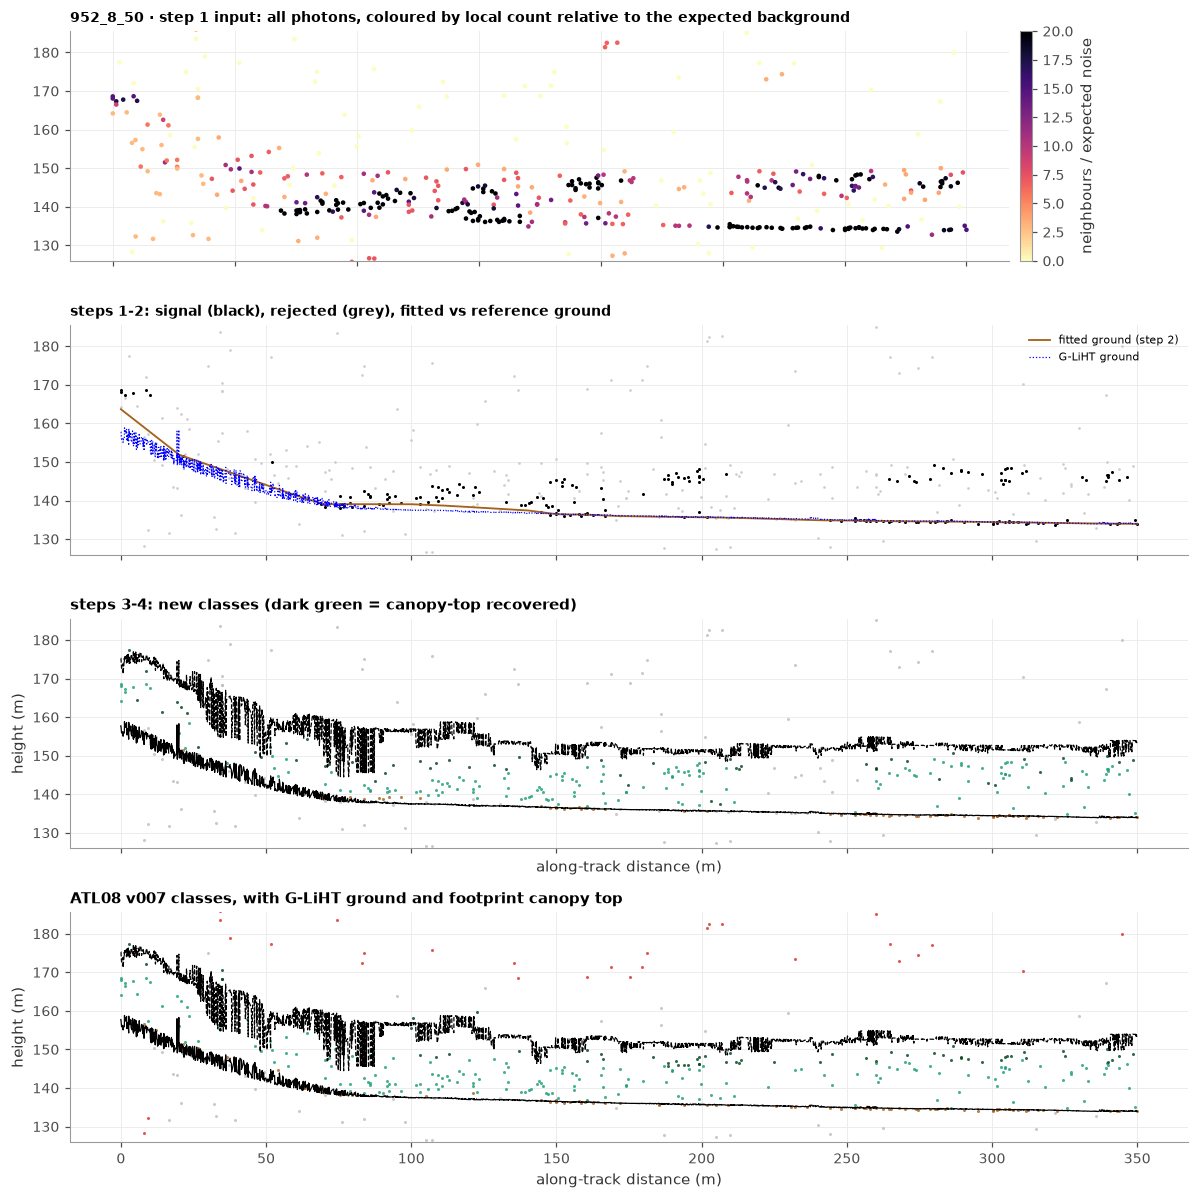

In [4]:
trk = evalph.groupby("track_id").agg(n=("ref_ch", "size"), ch=("ref_ch", "median"))
tid = trk[(trk.ch > 8) & (trk.n > 400)].n.idxmax() if ((trk.ch > 8) & (trk.n > 400)).any() else trk.n.idxmax()
p = allph[allph.track_id == tid].sort_values("x_atc")
x_start = p.loc[p.ref_label.isin(["ground", "canopy"]), "x_atc"].min()    # start where the reference coverage starts
p = p[(p.x_atc >= x_start) & (p.x_atc < x_start + 350)].copy()
sig, cnt, lam = ipl.noise_filter(p.x_atc.to_numpy(), p.height.to_numpy(), p.background_rate.to_numpy(), cfg)
x = p.x_atc - p.x_atc.min()
surf = p.height - p.relief_new
fig, axes = plt.subplots(4, 1, figsize=(11, 11), sharex=True, sharey=True)
sc = axes[0].scatter(x, p.height, c=cnt / np.maximum(lam, 0.1), s=4, cmap="magma_r", vmin=0, vmax=20)
plt.colorbar(sc, ax=axes[0], label="neighbours / expected noise", pad=0.01)
axes[0].set_title(f"{tid} · step 1 input: all photons, coloured by local count relative to the expected background", loc="left", fontsize=9)
axes[1].scatter(x[~sig], p.height[~sig], s=3, c="0.8", lw=0); axes[1].scatter(x[sig], p.height[sig], s=4, c="k", lw=0)
axes[1].plot(x, surf, c="#a6611a", lw=1.2, label="fitted ground (step 2)"); axes[1].plot(x, p.ref_ground, c="b", lw=0.8, ls=":", label="G-LiHT ground")
axes[1].set_title("steps 1-2: signal (black), rejected (grey), fitted vs reference ground", loc="left", fontsize=9); axes[1].legend(fontsize=7)
val.plot_profile(axes[2], p, "class_new", val.NEW_NAMES, title="steps 3-4: new classes (dark green = canopy-top recovered)")
val.plot_profile(axes[3], p, "atl08_class", val.ATL08_NAMES, title="ATL08 v007 classes, with G-LiHT ground and footprint canopy top")
lo, hi = np.nanpercentile(p.ref_ground, 1) - 8, np.nanpercentile(p.ref_top, 99) + 10
axes[0].set_ylim(lo, hi)
fig.tight_layout(); fig.savefig(FIG / "03_steps_example.png", dpi=150)

## Photon classification against the reference, by canopy height

Same layout as notebook 02. Summary rates for both classifiers in the table.

canopy_as_noise                                     \
classifier    ATL08 v007 photon classes reclassified photon classes (v0.1)   
canopy_height                                                                
0-1 m                             0.195                              0.090   
1-2 m                             0.154                              0.080   
10-15 m                           0.117                              0.189   
15-20 m                           0.138                              0.232   
2-5 m                             0.075                              0.093   
20+ m                             0.234                              0.379   
5-10 m                            0.104                              0.146   

                          canopy_recall                                     \
classifier    ATL08 v007 photon classes reclassified photon classes (v0.1)   
canopy_height                                                                
0-1 m                             0.550                              0.589   
1-2 m                             0.676                              0.706   
10-15 m                           0.822                              0.726   
15-20 m                           0.815                              0.705   
2-5 m                             0.831                              0.779   
20+ m                             0.737                              0.588   
5-10 m                            0.829                              0.757   

                       ground_as_canopy                                     \
classifier    ATL08 v007 photon classes reclassified photon classes (v0.1)   
canopy_height                                                                
0-1 m                             0.049                              0.060   
1-2 m                             0.060                              0.046   
10-15 m                           0.126                              0.063   
15-20 m                           0.159                              0.074   
2-5 m                             0.087                              0.062   
20+ m                             0.167                              0.103   
5-10 m                            0.106                              0.060   

                          ground_recall                                     
classifier    ATL08 v007 photon classes reclassified photon classes (v0.1)  
canopy_height                                                               
0-1 m                             0.905                              0.915  
1-2 m                             0.889                              0.938  
10-15 m                           0.819                              0.879  
15-20 m                           0.766                              0.820  
2-5 m                             0.872                              0.913  
20+ m                             0.703                              0.663  
5-10 m                            0.851                              0.908

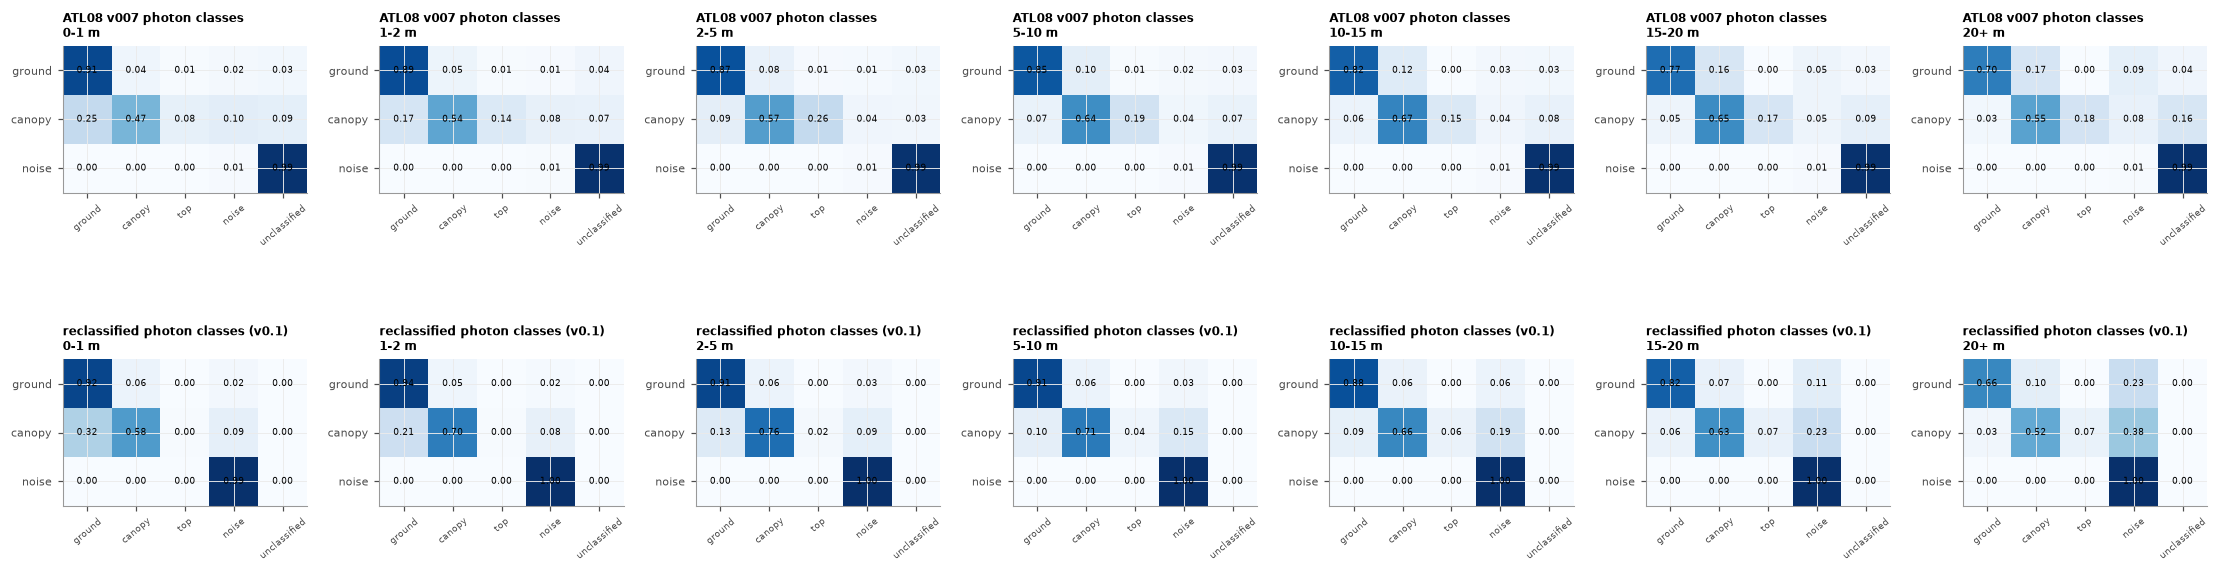

In [5]:
edges = [0, 1, 2, 5, 10, 15, 20, 60]
evalph = evalph.assign(ch_class=pd.cut(evalph.ref_ch, edges, right=False, labels=val.height_class_labels(edges)))
def rates(sub, col, names):
    t, tn = val.confusion(sub.ref_label, sub[col], names)
    tn = tn.reindex(index=["ground", "canopy", "noise"], columns=["ground", "canopy", "top", "noise", "unclassified"]).fillna(0)
    return {"ground_recall": tn.loc["ground", "ground"], "canopy_recall": tn.loc["canopy", ["canopy", "top"]].sum(),
            "ground_as_canopy": tn.loc["ground", ["canopy", "top"]].sum(),
            "canopy_as_noise": tn.loc["canopy", ["noise", "unclassified"]].sum(),
            "noise_as_canopy": tn.loc["noise", ["canopy", "top"]].sum()}, tn
rows = []
fig, axes = plt.subplots(2, len(edges) - 1, figsize=(2.9 * (len(edges) - 1), 6))
for j, c in enumerate(evalph.ch_class.cat.categories):
    sub = evalph[evalph.ch_class == c]
    for i, (col, names, nm) in enumerate([("atl08_class", val.ATL08_NAMES, val.PHOTON_ATL08), ("class_new", val.NEW_NAMES, val.PHOTON_NEW)]):
        ax = axes[i, j]
        if len(sub) < 50: ax.axis("off"); continue
        rt, tn = rates(sub, col, names)
        rows.append({"canopy_height": c, "classifier": nm, "n": len(sub), **rt})
        ax.imshow(tn.to_numpy(), cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(tn.shape[1]), tn.columns, rotation=40, fontsize=6); ax.set_yticks(range(3), tn.index, fontsize=7)
        for a in range(3):
            for b in range(tn.shape[1]):
                ax.text(b, a, f"{tn.iat[a, b]:.2f}", ha="center", va="center", fontsize=6)
        ax.set_title(f"{nm}\n{c}", fontsize=8, loc="left")
fig.tight_layout(); fig.savefig(FIG / "03_confusion_by_height.png", dpi=150)
rt = pd.DataFrame(rows); rt.to_csv(OUT / "photon_rates_by_height.csv", index=False)
rt.pivot_table(index="canopy_height", columns="classifier", values=["ground_as_canopy", "canopy_as_noise", "canopy_recall", "ground_recall"]).round(3)

## Ground surface error by canopy height

For photons the reference labels as ground: the height of each **fitted ground surface** at that photon minus the G-LiHT/UAV
reference ground. Median (bias) and 90th percentile of the absolute error, for the ground from the **reclassified photons**
and the ground drawn through the **ATL08 v007** ground photons. A ground surface that sits too high makes every height above it
too low (tall forest); too low makes heights too high.

,new_median,new_p90_abs,atl08_median,atl08_p90_abs
ch_class,,,,
0-1 m,-0.00,0.36,-0.00,0.31
1-2 m,0.01,0.27,0.01,0.29
2-5 m,-0.01,0.36,-0.02,0.39
5-10 m,-0.00,0.40,-0.02,0.44
10-15 m,-0.03,0.46,-0.07,0.51
15-20 m,0.02,0.73,-0.04,1.02
20+ m,0.03,1.41,-0.03,1.43


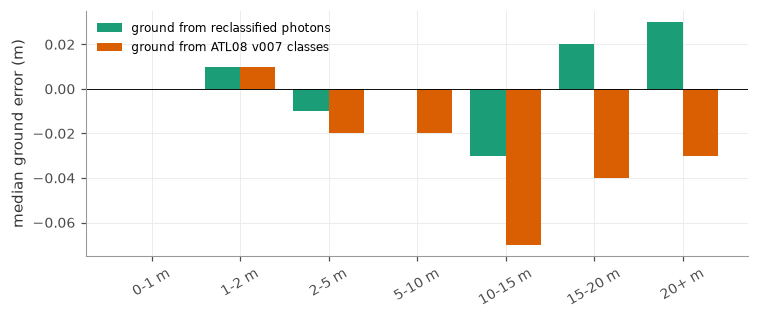

In [6]:
g = evalph[evalph.ref_label == "ground"].copy()
g["err_new"] = (g.height - g.relief_new) - g.ref_ground
g["err_atl08"] = (g.height - g.relief_atl08) - g.ref_ground
tab = g.groupby("ch_class", observed=False)[["err_new", "err_atl08"]].agg(["median", lambda v: np.nanpercentile(np.abs(v), 90)]).round(2)
tab.columns = ["new_median", "new_p90_abs", "atl08_median", "atl08_p90_abs"]
fig, ax = plt.subplots(figsize=(7, 3))
xx = np.arange(len(tab))
ax.bar(xx - 0.2, tab.new_median, 0.4, label="ground from reclassified photons", color=val.SCHEME_COLORS[val.LABEL_NEW])
ax.bar(xx + 0.2, tab.atl08_median, 0.4, label="ground from ATL08 v007 classes", color=val.SCHEME_COLORS[val.LABEL_CHECK])
ax.set_xticks(xx, tab.index, rotation=30); ax.axhline(0, c="k", lw=0.6); ax.set_ylabel("median ground error (m)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "03_ground_error.png", dpi=150)
tab

## Day vs night, strong vs weak beams

The same photon error rates as above, split by solar elevation (day > 0°) and beam strength. Daytime solar background is the
main source of noise photons, so this is where the two classifications should differ most.

In [7]:
evalph["light"] = np.where(evalph.solar_elevation > 0, "day", "night")
evalph["beam"] = np.where(evalph.strong, "strong", "weak")
rows = []
for (l, b), sub in evalph.groupby(["light", "beam"]):
    for col, names, nm in [("atl08_class", val.ATL08_NAMES, val.PHOTON_ATL08), ("class_new", val.NEW_NAMES, val.PHOTON_NEW)]:
        rows.append({"light": l, "beam": b, "classifier": nm, "n": len(sub), **rates(sub, col, names)[0]})
pd.DataFrame(rows).round(3)

,light,beam,classifier,n,ground_recall,canopy_recall,ground_as_canopy,canopy_as_noise,noise_as_canopy
0,day,strong,ATL08 v007 photon classes,451480,0.881,0.818,0.076,0.111,0.002
1,day,strong,reclassified photon classes (v0.1),451480,0.925,0.789,0.060,0.093,0.002
2,day,weak,ATL08 v007 photon classes,308678,0.865,0.672,0.073,0.235,0.003
3,day,weak,reclassified photon classes (v0.1),308678,0.883,0.426,0.041,0.447,0.001
4,night,strong,ATL08 v007 photon classes,36965,0.875,0.773,0.077,0.109,0.096
5,night,strong,reclassified photon classes (v0.1),36965,0.895,0.759,0.075,0.124,0.089
6,night,weak,ATL08 v007 photon classes,9772,0.861,0.606,0.056,0.233,0.033
7,night,weak,reclassified photon classes (v0.1),9772,0.812,0.341,0.041,0.558,0.012


## Parameter sensitivity, per region (guarding against overfitting)

The method is meant for all circumpolar tiles, so a setting is judged by how it does in **each** region (Interior, Kenai,
Seward), not on the pooled photons. The table reports every region and the **worst region** per setting; a change is only a
candidate for the next config version if it does not degrade any region (methods §7). The config is **not** changed here.

In [8]:
import copy, itertools
rng = np.random.default_rng(0)
base = []
for reg, g in evalph.groupby("region"):                       # up to 25 tracks per region, so no region dominates
    trk = g.track_id.unique()
    base.append(allph[allph.track_id.isin(rng.choice(trk, size=min(25, len(trk)), replace=False))])
base = pd.concat(base)
rows = []
for k, hw, mr in itertools.product([2.0, 3.0, 4.0], [0.4, 0.6, 0.9], [0.3, 0.5, 1.0]):
    c2 = copy.deepcopy(cfg)
    c2["reclass"]["noise"]["k_sigma"] = k; c2["reclass"]["ground"]["halfwidth_m"] = hw; c2["reclass"]["canopy"]["min_relief_m"] = mr
    r = ipl.reclassify(base, c2)
    for reg, e in r[r.ref_label.isin(["ground", "canopy", "noise"])].groupby("region"):
        rt, _ = rates(e, "class_new", val.NEW_NAMES)
        rows.append({"k_sigma": k, "ground_halfwidth": hw, "min_relief": mr, "region": reg, **rt})
sens = pd.DataFrame(rows); sens.to_csv(OUT / "sensitivity_grid_by_region.csv", index=False)
sens["score"] = sens.canopy_recall + sens.ground_recall - sens.ground_as_canopy - sens.noise_as_canopy
wide = sens.pivot_table(index=["k_sigma", "ground_halfwidth", "min_relief"], columns="region", values="score")
wide["worst_region"] = wide.min(axis=1)
base_setting = (cfg["reclass"]["noise"]["k_sigma"], cfg["reclass"]["ground"]["halfwidth_m"], cfg["reclass"]["canopy"]["min_relief_m"])
print("current config v0.1:", base_setting, "| worst-region score", round(wide.loc[base_setting, "worst_region"], 3) if base_setting in wide.index else "n/a")
wide.sort_values("worst_region", ascending=False).head(10).round(3)

current config v0.1: (3.0, 0.6, 0.5) | worst-region score 1.373


,,region,Interior,Kenai,Seward,worst_region
k_sigma,ground_halfwidth,min_relief,,,,
2.0,0.6,0.5,1.589,1.471,1.373,1.373
3.0,0.6,0.5,1.589,1.469,1.373,1.373
4.0,0.6,0.5,1.588,1.473,1.368,1.368
2.0,0.6,0.3,1.573,1.458,1.355,1.355
3.0,0.6,0.3,1.573,1.458,1.355,1.355
4.0,0.6,0.3,1.572,1.462,1.351,1.351
3.0,0.9,0.5,1.562,1.490,1.316,1.316
2.0,0.9,0.5,1.562,1.495,1.316,1.316
4.0,0.9,0.5,1.561,1.495,1.311,1.311


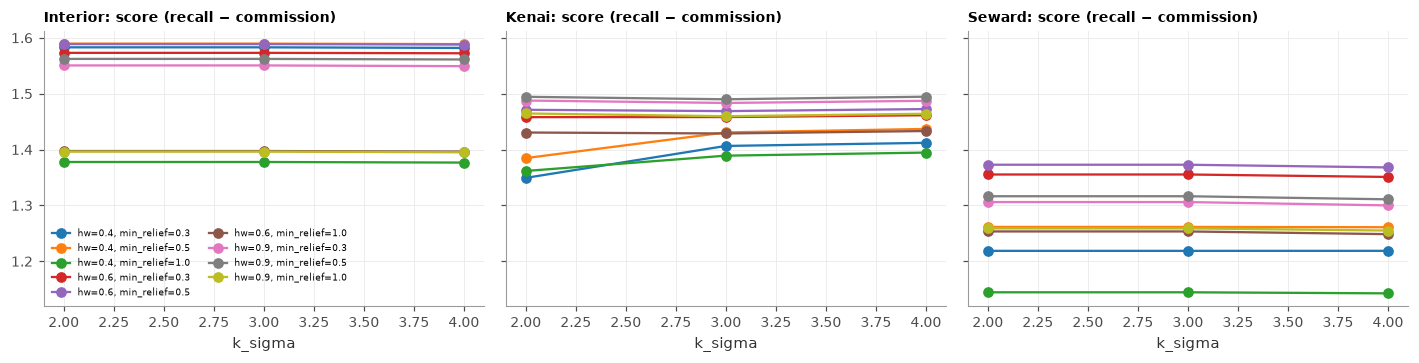

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (reg, g) in zip(axes, sens.groupby("region")):
    for (hw, mr), gg in g.groupby(["ground_halfwidth", "min_relief"]):
        ax.plot(gg.k_sigma, gg.score, marker="o", label=f"hw={hw}, min_relief={mr}")
    ax.set_xlabel("k_sigma"); ax.set_title(f"{reg}: score (recall − commission)", loc="left", fontsize=9)
axes[0].legend(fontsize=6, ncol=2)
fig.tight_layout(); fig.savefig(FIG / "03_sensitivity_by_region.png", dpi=150)

## Benchmark: random forest trained on the reference labels

Features per photon: height above the fitted ground, local count relative to the expected background, background rate, solar
elevation, beam strength, ATL03 v007 photon weight (YAPC) and confidence. Trained on one region, tested on the others.
Adopted only if it clearly beats the rules (plan §4.2).

In [10]:
from sklearn.ensemble import RandomForestClassifier
def features(d):
    s, c, l = [], [], []
    out = []
    for tid, g in d.groupby("track_id"):
        _, cnt, lam = ipl.noise_filter(g.x_atc.to_numpy(), g.height.to_numpy(), g.background_rate.to_numpy(), cfg)
        out.append(pd.DataFrame({"idx": g.index, "cnt_ratio": cnt / np.maximum(lam, 0.05)}))
    f = pd.concat(out).set_index("idx")
    X = pd.DataFrame({"relief": d.relief_new, "cnt_ratio": f.cnt_ratio.reindex(d.index), "bg": np.log10(d.background_rate.clip(lower=1)),
                      "sun": d.solar_elevation, "strong": d.strong.astype(int),
                      "yapc": d.get("yapc_score", pd.Series(0, index=d.index)), "cnf": d.get("atl03_cnf", pd.Series(0, index=d.index))})
    return X.fillna(-999)
lab = evalph.copy()
X = features(lab); y = lab.ref_label
rows = []
for test_region in lab.region.unique():
    tr, te = lab.region != test_region, lab.region == test_region
    if te.sum() < 500 or tr.sum() < 500: continue
    rf = RandomForestClassifier(n_estimators=150, max_depth=14, n_jobs=-1, random_state=0, class_weight="balanced").fit(X[tr], y[tr])
    pred = rf.predict(X[te])
    code = pd.Series(pred).map({"noise": 0, "ground": 1, "canopy": 2}).to_numpy()
    rows.append({"test_region": test_region, "classifier": "random forest on reference labels (benchmark)", "n": int(te.sum()), **rates(lab[te].assign(rf=code), "rf", val.NEW_NAMES)[0]})
    rows.append({"test_region": test_region, "classifier": val.PHOTON_NEW, "n": int(te.sum()), **rates(lab[te], "class_new", val.NEW_NAMES)[0]})
    rows.append({"test_region": test_region, "classifier": val.PHOTON_ATL08, "n": int(te.sum()), **rates(lab[te], "atl08_class", val.ATL08_NAMES)[0]})
bench = pd.DataFrame(rows); bench.to_csv(OUT / "benchmark_rf.csv", index=False)
bench.round(3)

,test_region,classifier,n,ground_recall,canopy_recall,ground_as_canopy,canopy_as_noise,noise_as_canopy
0,Interior,random forest on reference labels (benchmark),337564,0.962,0.817,0.037,0.019,0.004
1,Interior,reclassified photon classes (v0.1),337564,0.953,0.746,0.031,0.147,0.001
2,Interior,ATL08 v007 photon classes,337564,0.925,0.793,0.042,0.138,0.002
3,Kenai,random forest on reference labels (benchmark),391836,0.796,0.848,0.194,0.072,0.004
4,Kenai,reclassified photon classes (v0.1),391836,0.814,0.695,0.113,0.214,0.004
5,Kenai,ATL08 v007 photon classes,391836,0.790,0.764,0.117,0.154,0.004
6,Seward,random forest on reference labels (benchmark),77495,0.804,0.756,0.189,0.000,0.010
7,Seward,reclassified photon classes (v0.1),77495,0.827,0.631,0.136,0.060,0.001
8,Seward,ATL08 v007 photon classes,77495,0.737,0.778,0.230,0.027,0.006


## Results
Summarise after review: changes in ground→canopy (short vegetation) and canopy→noise (tall forest) relative to ATL08 v007, ground
surface bias, any sensitivity setting that should become config v0.2, and whether the random forest beats the rules.